In [1]:
import numpy as np
import scipy as sp

import matplotlib.pyplot as plt
%matplotlib inline

from scipy.integrate import simps
from scipy.integrate import quad
from scipy import interpolate

import importlib

from gas_props import helium_cv_ideal
from gas_props import helium_cp





## Helium & Nitrogen properties

In [2]:
# Helium viscosity and conductivity from NIST
# https://webbook.nist.gov/chemistry/fluid/

T4, Ent4, Cp4, Vis4, Cond4 = np.loadtxt('thermalProp/helium_prop.txt', delimiter='\t',  \
                                        skiprows=1, usecols=[0, 5, 8, 11, 12], unpack=True)

HeCp    = interpolate.interp1d(T4, Cp4*1e3, fill_value="extrapolate")
HeVis   = interpolate.interp1d(T4, Vis4)
HeCond  = interpolate.interp1d(T4, Cond4, bounds_error=False, fill_value=0.05)

HeEnt  = interpolate.interp1d(T4, Ent4)

In [3]:
# Helium viscosity and conductivity from NIST
# https://webbook.nist.gov/chemistry/fluid/

T_N, Ent_N, Cp_N, Vis_N, Cond_N = np.loadtxt('thermalProp/nitrogen_prop.txt', delimiter='\t',  \
                                             skiprows=1, usecols=[0, 5, 8, 11, 12], unpack=True)

NCp    = interpolate.interp1d(T_N, Cp_N*1e3)
NVis   = interpolate.interp1d(T_N, Vis_N)
NCond  = interpolate.interp1d(T_N, Cond_N)

NEnt  = interpolate.interp1d(T_N, Ent_N)

In [4]:
def power2mdot(p, gas='He'):
    if gas == 'He':
        L = 84.5/0.004
    elif gas == 'N':
        L = 2.7928e3/0.01401
    return p/L


def mdot2power(mdot, gas='He'):
    if gas == 'He':
        L = 84.5/0.004
    elif gas == 'N':
        L = 2.7928e3/0.01401
    return mdot*L

    
def mdot2SLPM(mdot, gas='He'):
    '''
    Converting from kg/s to standard liters per minute (SLPM)
    '''
    if gas == 'He':
        DensATStp = 4.003/22.41*1e-3 #kg/L
    elif gas == 'N':
        DensATStp = 28.02/22.41*1e-3 #kg/L

    SLPM = 60 * ( mdot / DensATStp )
    return SLPM

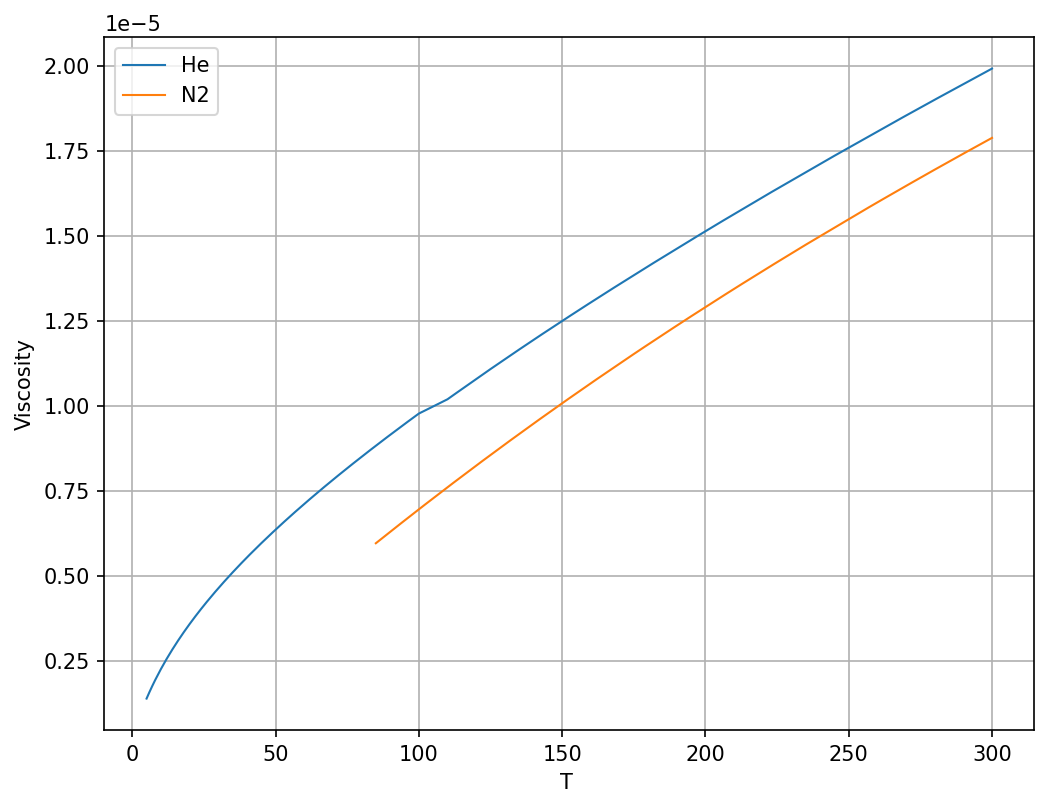

In [5]:
T = np.arange(5,301,1)


fig, ax1 = plt.subplots(dpi=150)


plt.plot(T, HeVis(T), label='He')

plt.plot(T[80:], NVis(T[80:]), label='N2')

    
# plt.h
    
plt.xlabel('T ')
plt.ylabel('Viscosity')

# plt.ylim([0,50])

plt.legend()
plt.grid()

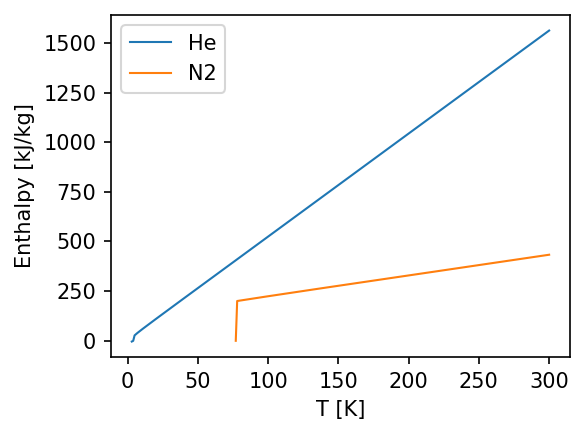

In [6]:
T = np.arange(3,301,1)


fig, ax1 = plt.subplots(figsize=(4,3),dpi=150)


plt.plot(T, HeEnt(T), label='He')

plt.plot(T[74:], NEnt(T[74:])-NEnt(77.35), label='N2')

    
# plt.xscale('log')   
# plt.yscale('log')
    
plt.xlabel('T [K]')
plt.ylabel('Enthalpy [kJ/kg]')

# plt.ylim([10,22])

plt.legend()
# plt.grid()

plt.tight_layout()

# plt.savefig('Enthalpy.png', dpi=150)

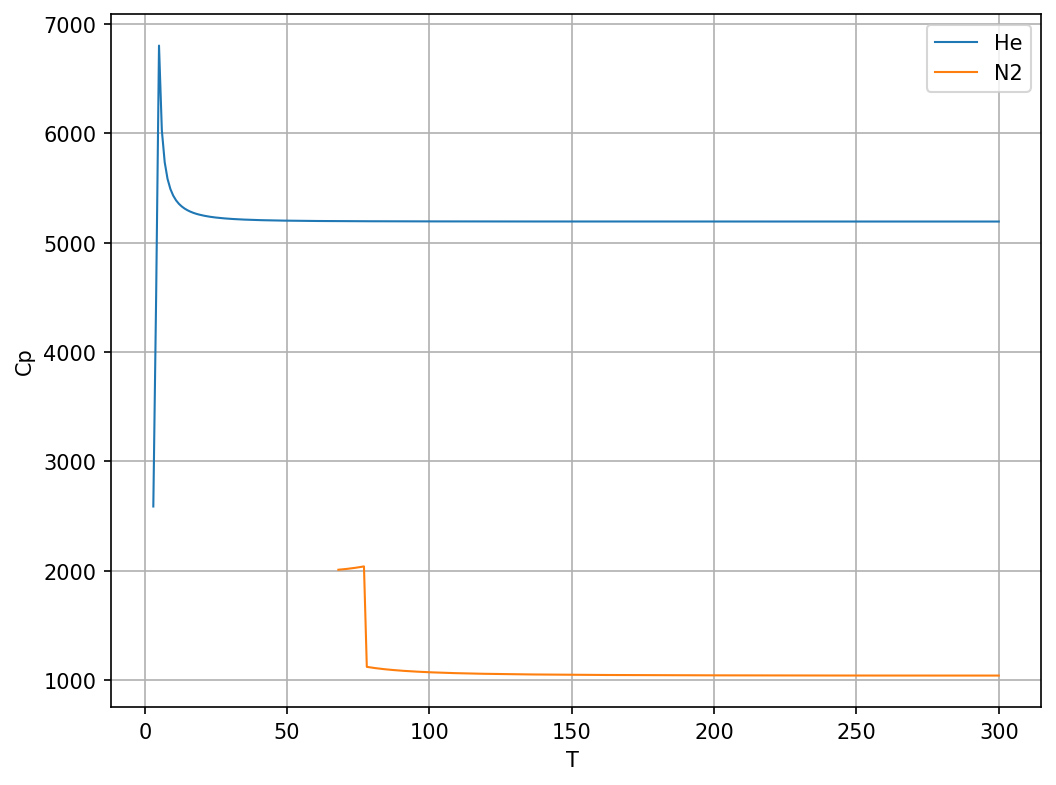

In [7]:
T = np.arange(3,301,1)


fig, ax1 = plt.subplots(dpi=150)


plt.plot(T, HeCp(T), label='He')

plt.plot(T[65:], NCp(T[65:]), label='N2')

    
# plt.xscale('log')   
# plt.yscale('log')
    
plt.xlabel('T ')
plt.ylabel('Cp')

# plt.ylim([10,22])

plt.legend()
plt.grid()

In [8]:
NCp(300)

array(1041.4)

## Reynolds number

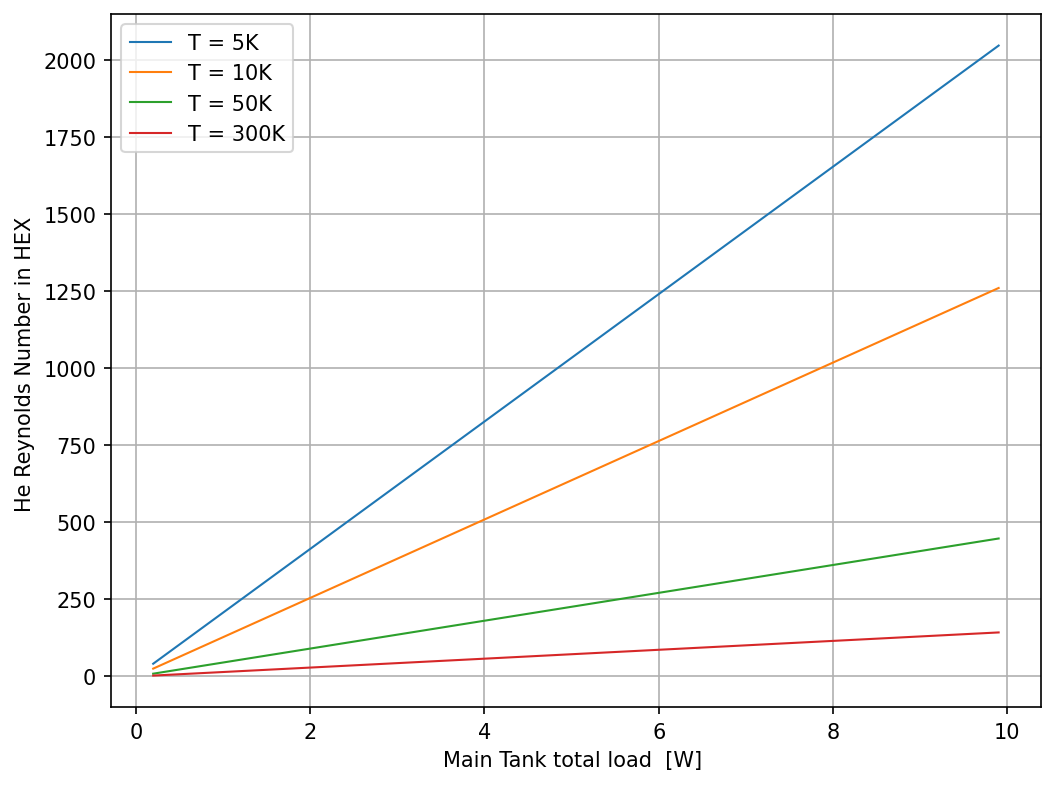

In [9]:


d  = 0.125 * 0.0254 # in m

power = np.arange(0.2, 10.0, 0.1)
mdot = power2mdot(power, gas='He')  # kg per second
N_tube = 66


fig, ax1 = plt.subplots(dpi=150)

for T in [5,10,50,300]:
    Re  = mdot/N_tube *4 /(HeVis(T)*np.pi*d)

    plt.plot(power, Re, label='T = %dK'%T)

     
plt.xlabel('Main Tank total load  [W] ')
plt.ylabel('He Reynolds Number in HEX ')

# plt.ylim([0,50])

plt.legend()
plt.grid()

plt.savefig('HEX_vis.png', dpi=150)

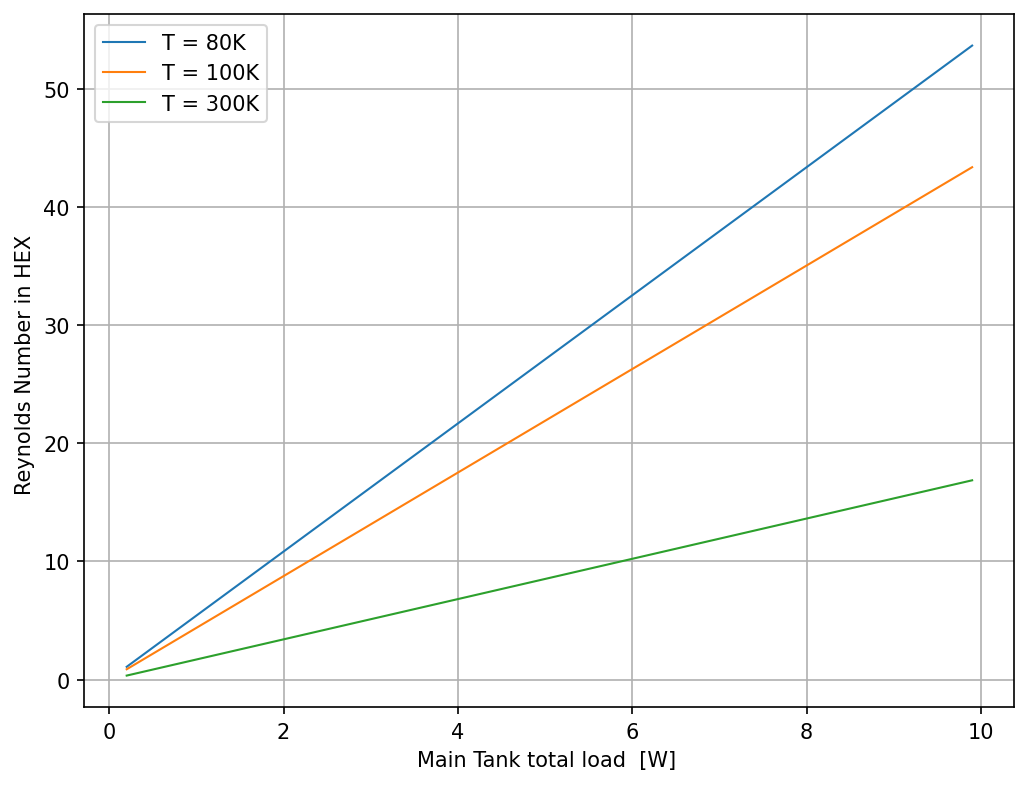

In [10]:


d  = 0.125 * 0.0254 # in m

power = np.arange(0.2, 10.0, 0.1)
mdot = power2mdot(power, gas='N')  # kg per second
N_tube = 66


fig, ax1 = plt.subplots(dpi=150)

for T in [80,100,300]:
    Re  = mdot/N_tube *4 /(NVis(T)*np.pi*d)

    plt.plot(power, Re, label='T = %dK'%T)

     
plt.xlabel('Main Tank total load  [W] ')
plt.ylabel('Reynolds Number in HEX ')

# plt.ylim([0,50])

plt.legend()
plt.grid()

# plt.savefig('HEX_vis.png', dpi=150)d()

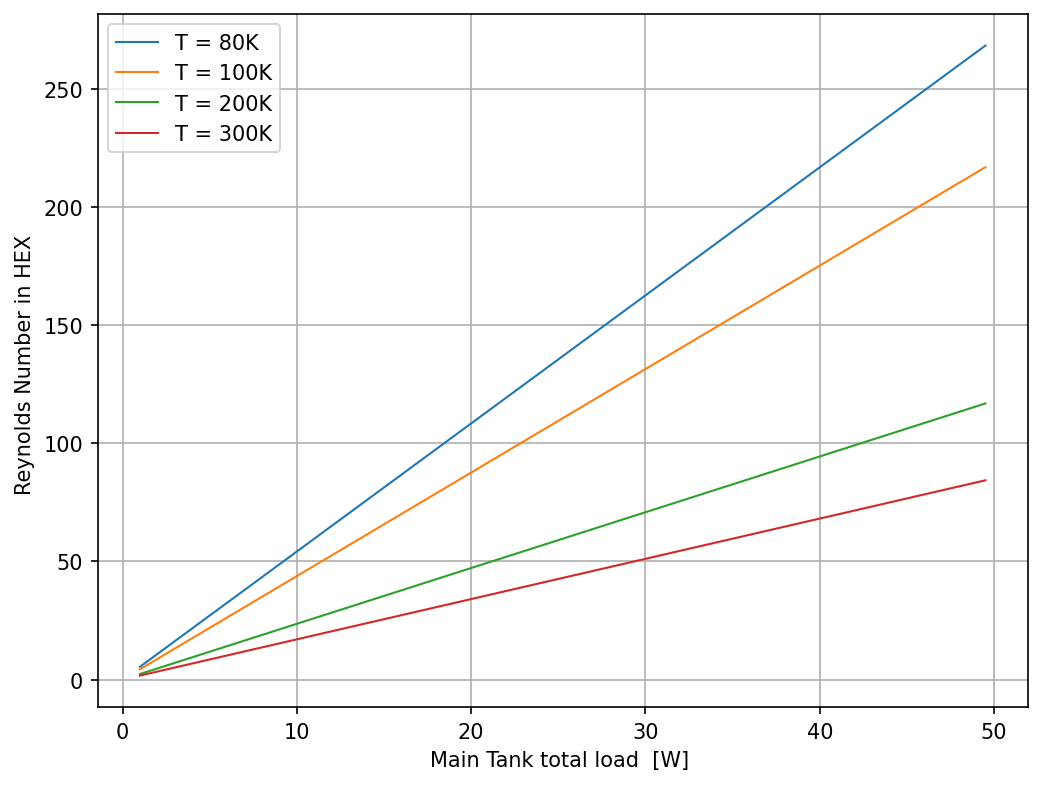

In [11]:
d  = 0.125 * 0.0254 # in m

power = np.arange(1, 50.0, 0.5)
mdot = power2mdot(power, gas='N')  # kg per second
N_tube = 66


fig, ax1 = plt.subplots(dpi=150)

for T in [80,100,200,300]:
    Re  = mdot/N_tube *4 /(NVis(T)*np.pi*d)

    plt.plot(power, Re, label='T = %dK'%T)

    
# plt.h
    
plt.xlabel('Main Tank total load  [W] ')
plt.ylabel('Reynolds Number in HEX ')

# plt.ylim([0,50])

plt.legend()
plt.grid()

## simple exponetial model

Use the time gas stayed in the heat exchanger to estimate the heat transfer.

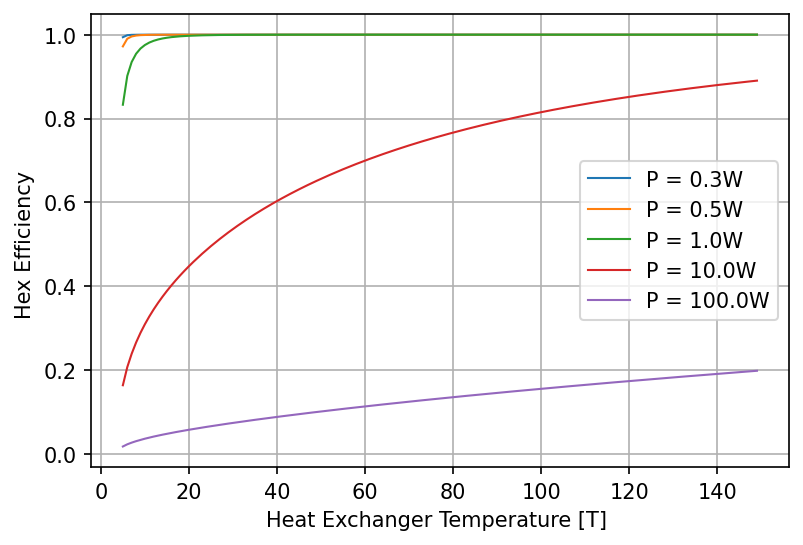

In [167]:


power = [0.35, 0.5, 1.,10,100]

Nu = 3.6      # Nusselt number
Ts = np.arange(5,150,1)

d  = 0.125 * 0.0254 # in m
l  = 0.075          # in meter
N_tube = 66

E = []

for p in power:
    mdot = p/85*0.004  # kg per second
    K = HeCond(Ts)
    ratio = N_tube*np.pi*Nu*K*l/mdot/HeCp(Ts)
    E.append(1-np.exp(-ratio))
    
E = np.array(E)


fig, ax1 = plt.subplots(dpi=150)

for i,p in enumerate(power):
    plt.plot(Ts, E[i], label='P = %1.1fW'%p)


    
plt.xlabel('Heat Exchanger Temperature [T] ')
plt.ylabel('Hex Efficiency ')

# plt.ylim([0,50])

plt.legend()
plt.grid()


## Fancy heat exchange model

Divide the tube into N sections, calculate the heat transfer in each section

In [12]:
def HexEff(T_hex, T0, power=1, gas = 'He', N=1000):
    '''
    power[W] : power dump on the main tank
    gas      : type of gas, 'He' or 'N'
    '''
    
    if gas == 'He':
        Cond = HeCond
        Cp   = HeCp
    
    elif gas == 'N':
        Cond = NCond
        Cp   = NCp
    
    
    l  = 0.075
    dx = l/N
    d  = 0.125 * 0.0254 # in m
    x  = np.linspace(0,l,N+1)

    mdot   = power2mdot(power, gas=gas) # evaporative rate, kg per second
    N_tube = 66
    Nu     = 3.6
    
    T   = np.zeros(x.shape)
    T[0]= T0

    for i in range(1,x.shape[0]):
        h = N_tube*Nu*Cond(T[i-1])/d
        T[i] = (h * np.pi*d*dx*T_hex + T[i-1]*mdot*Cp(T[i-1]))/(mdot*Cp(T[i-1])+h*np.pi*d*dx)
        
    # for i in range(2):
    #     h = N_tube*Nu*Cond(T[1:])/d
    #     Cp_mid =  (Cp(T[:-1]) + Cp(T[1:]))*0.5
    #     T[1:] = (h * np.pi*d*dx*T_hex + T[:-1]*mdot*Cp_mid)/(mdot*Cp_mid+h*np.pi*d*dx)
    
    # h = N_tube*Nu*Cond(T[1:])/d
    # dp =  h * np.pi*d*dx*(T_hex-T[1:]) + (Cp(T[:-1])+Cp(T[1:]))*0.5*mdot*(T[:-1]-T[1:])

    
    return x,T

In [13]:
def getDt(dt, a, maxdT):
    dt=dt*a
    
    dt[np.where(dt>maxdT)]=maxdT
    dt[np.where(dt<-1*maxdT)]=-1*maxdT
    
    return dt


 1.2281842209915794e-15


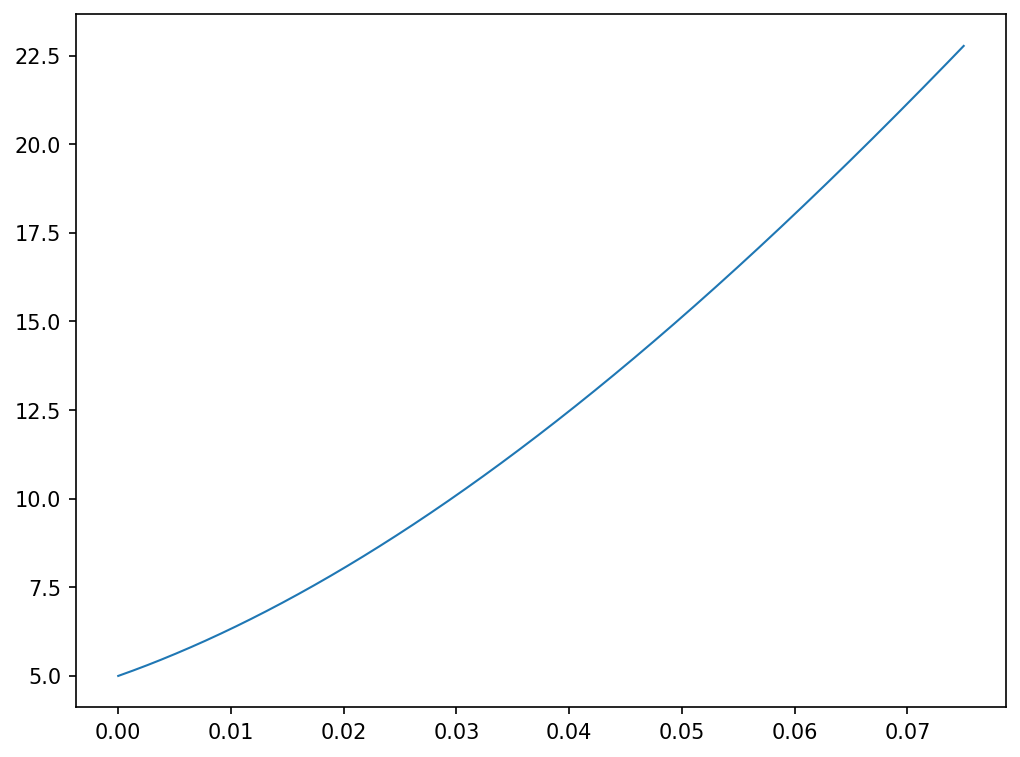

In [18]:
    
gas='He'
T0 = 5
T_hex = 100

    
Cond = HeCond
Cp   = HeCp


N  = 2000
l  = 0.075
dx = l/N
d  = 0.125 * 0.0254 # in m
x  = np.linspace(0,l,N+1)

mdot   = power2mdot(20, gas=gas) # evaporative rate, kg per second
N_tube = 66
Nu     = 3.6

x,T   = HexEff(T_hex, T0, power=1, gas = gas, N=N)
T[0] = T0

a = 1e-2

for i in range(100):
        
        dt = 1e-2
        T2 = T.copy() + dt
        h = N_tube*Nu*Cond(T[1:])/d
        dp =  h * np.pi*d*dx*(T_hex-T[1:]) + Cp(T[1:])*mdot*(T[:-1]-T[1:])

        h2 = N_tube*Nu*Cond(T[1:])/d
        dp2 =  h2 * np.pi*d*dx*(T_hex-T2[1:]) + Cp(T2[1:])*mdot*(T2[:-1]-T2[1:])

        fnot = (dp2-dp)/(dt)

        T[1:]  =  T[1:] + dp*0.1
        
        # print(dp/fnot)
        
        # print(T,)
        
print('\n',dp.max())

# plt.plot(T)
plt.plot(x, HexEff(T_hex, T0, power=20, gas = gas, N=N)[1])
# plt.plot(dp)
# plt.plot(fnot)


#### how many sections do we need?

20 46.570793870524064
50 48.390206824957616
100 49.01600428936719
200 49.33344739848419
500 49.52505530359876
1000 49.58917955398056
2000 49.621279137313266
5000 49.640552677294835


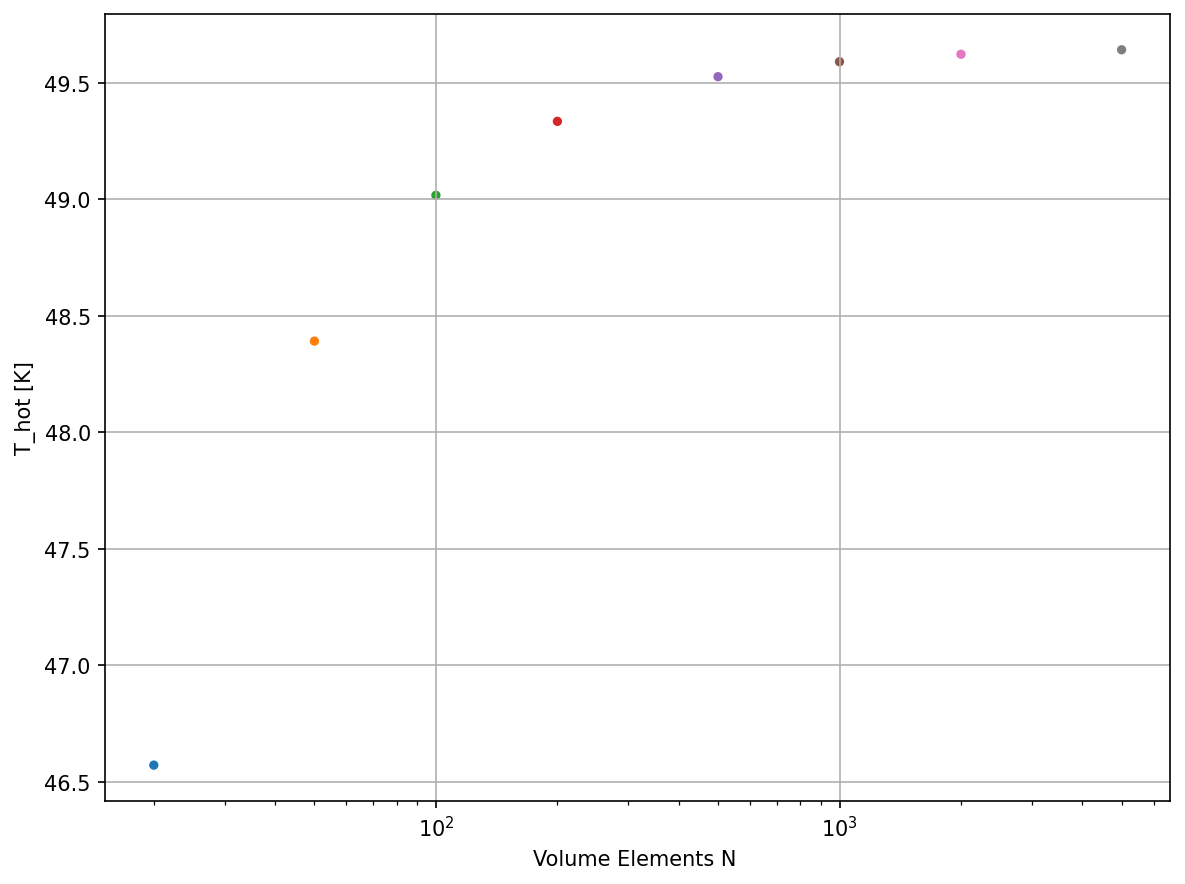

In [15]:

Ns = [20,50,100,200,500,1000,2000,5000] 

fig, ax1 = plt.subplots(dpi=150)

for i, N in enumerate(Ns):
    x,T = HexEff(100, T0=5, power=10, gas='He', N=N)
    
    plt.scatter(Ns[i], T[-1], s=20)
    print(Ns[i],T[-1])

    
plt.xscale('log')
# plt.yscale('log')
# plt.legend()

plt.xlabel('Volume Elements N ')
plt.ylabel('T_hot [K]')


plt.grid()
plt.tight_layout()

plt.savefig('HEX_conv.png')

#### Helium cooling efficiency

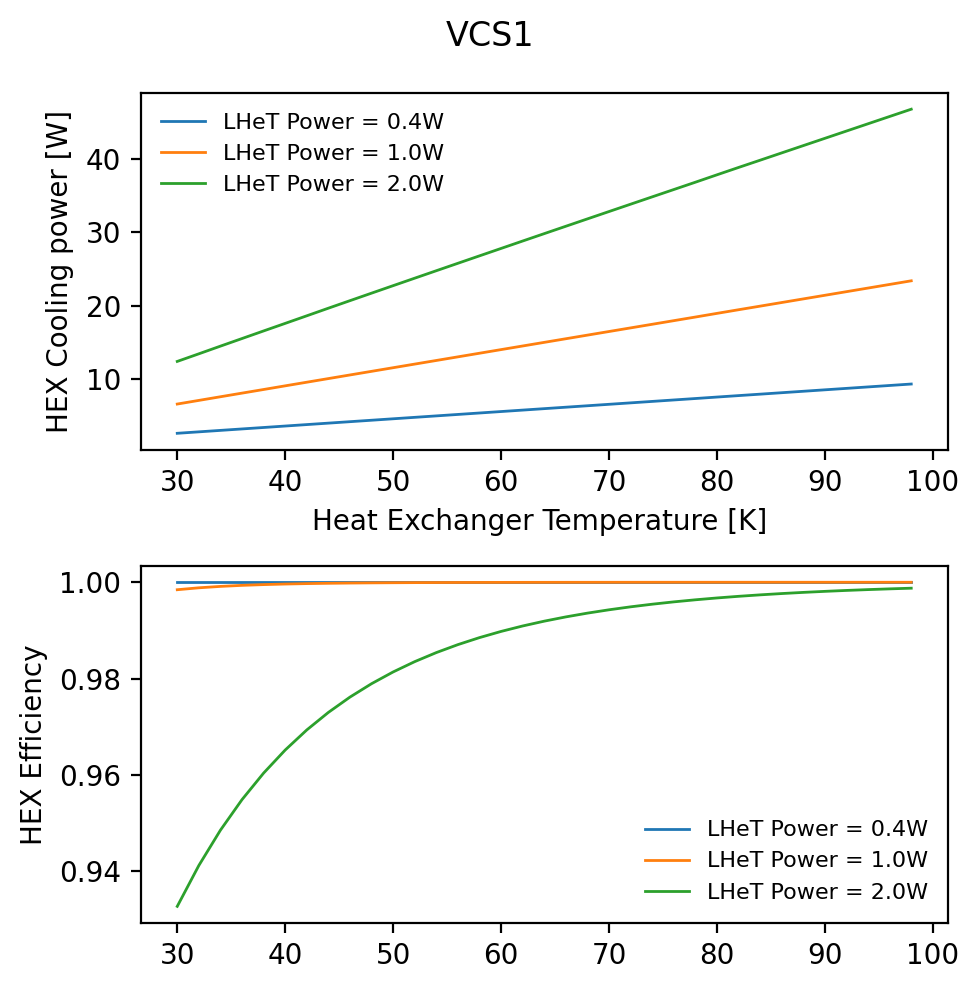

In [62]:
fig, ax = plt.subplots(2,1,figsize=(5,5),dpi=200)

for p in [0.4, 1, 2., ]:

    T2s  = np.arange(30,100,2)
    Eff  = []
    CoolPower = []
    mdot = power2mdot(p)

    for T2 in T2s:
        x,T = HexEff(T2, T0=4.2,  power=p, gas='He')
        Eff.append((T[-1]-T[0])/(T2-T[0])) 
        CoolPower.append((quad(HeCp, T[0], T[-1], epsrel=1e-3)[0])*mdot)
    
    ax[1].plot(T2s, Eff, label='LHeT Power = %1.1fW'%p)
    ax[0].plot(T2s, CoolPower, label='LHeT Power = %1.1fW'%p)

ax[0].set_xlabel('Heat Exchanger Temperature [K] ')

ax[1].set_ylabel('HEX Efficiency')
ax[0].set_ylabel('HEX Cooling power [W]')

# plt.ylim([0,50])
ax[1].legend(frameon=0, fontsize=8)
# ax[0].grid()

ax[0].legend(frameon=0, fontsize=8)
# ax[1].grid()

plt.suptitle('VCS1')

plt.tight_layout()

# plt.savefig('HEX_eff_vcs1.png')

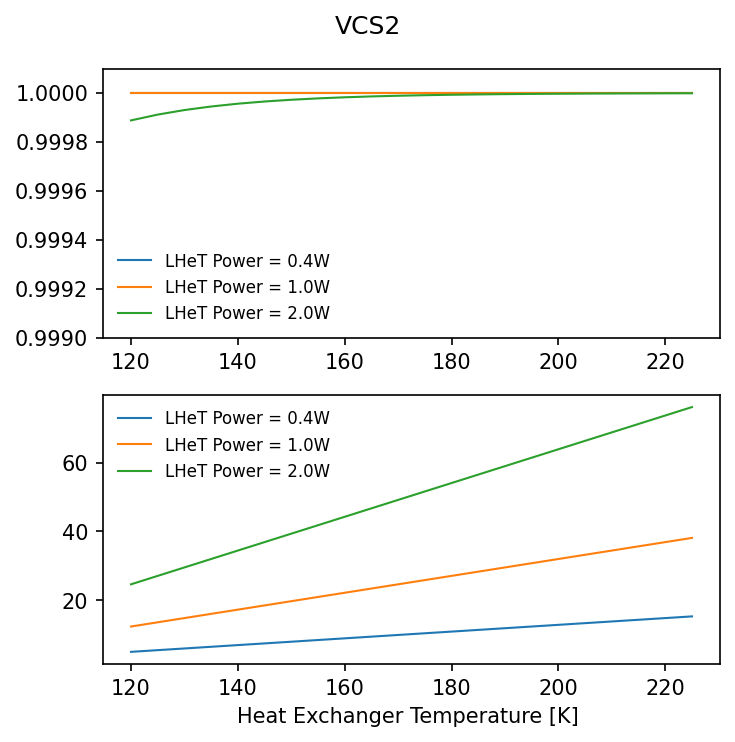

In [61]:
fig, ax = plt.subplots(2,1,figsize=(5,5),dpi=150)

for p in [0.4, 1, 2]:

    T2s  = np.arange(120,230,5)
    Eff  = []
    CoolPower = []
    mdot = power2mdot(p)

    for T2 in T2s:
        x,T = HexEff(T2, T0=70,  power=p, gas='He')
        Eff.append((T[-1]-T[0])/(T2-T[0])) 
        CoolPower.append((quad(HeCp, T[0], T[-1], epsrel=1e-3)[0])*mdot)
    
    ax[0].plot(T2s, Eff, label='LHeT Power = %1.1fW'%p)
    ax[1].plot(T2s, CoolPower, label='LHeT Power = %1.1fW'%p)

ax[1].set_xlabel('Heat Exchanger Temperature [K] ')

# ax[0].set_ylabel('Heat Exchanger Efficiency')
# ax[1].set_ylabel('Heat Exchanger Cooling power [W]')

ax[0].set_ylim([0.999,1.0001])
ax[0].legend(frameon=0, fontsize=8)
# ax[0].grid()

ax[1].legend(frameon=0, fontsize=8)
# ax[1].grid()

plt.suptitle('VCS2')
plt.tight_layout()

# plt.savefig('HEX_eff_vcs2.png')

### Helium cooling power single plot

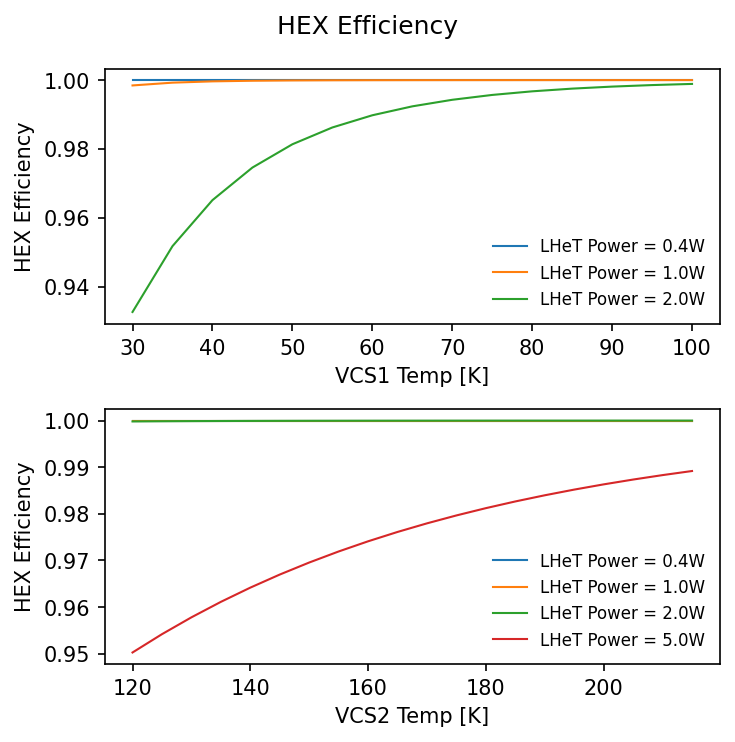

In [33]:
fig, ax = plt.subplots(2,1,figsize=(5,5),dpi=150)

for p in [0.4, 1, 2,]:

    T2s  = np.arange(30,101,5)
    Eff  = []
    CoolPower = []
    mdot = power2mdot(p)

    for T2 in T2s:
        x,T = HexEff(T2, T0=4.2,  power=p, gas='He')
        Eff.append((T[-1]-T[0])/(T2-T[0])) 
        CoolPower.append((quad(HeCp, T[0], T[-1], epsrel=1e-3)[0])*mdot)
    
    ax[0].plot(T2s, Eff, label='LHeT Power = %1.1fW'%p)

ax[0].set_xlabel('VCS1 Temp [K]') 
ax[0].set_ylabel('HEX Efficiency')    
ax[0].legend(frameon=0, fontsize=8)


for p in [0.4, 1, 2, 5]:

    T2s  = np.arange(120,220,5)
    Eff  = []
    CoolPower = []
    mdot = power2mdot(p)

    for T2 in T2s:
        x,T = HexEff(T2, T0=30,  power=p, gas='He')
        Eff.append((T[-1]-T[0])/(T2-T[0])) 
        CoolPower.append((quad(HeCp, T[0], T[-1], epsrel=1e-3)[0])*mdot)
    
    ax[1].plot(T2s, Eff, label='LHeT Power = %1.1fW'%p)   

ax[1].set_xlabel('VCS2 Temp [K]') 
ax[1].set_ylabel('HEX Efficiency')    
ax[1].legend(frameon=0, fontsize=8)
# ax[1].grid()

plt.suptitle('HEX Efficiency')

plt.tight_layout()

# plt.savefig('HEX_eff_vcs1.png')

### cooling power

In [116]:
slpm = 9
mdot =  slpm/60/22.41*0.004003
Tc = 16.6
TV1 = 62.8
TV2 = 175

V1_coolpower = (quad(HeCp, Tc, TV1, epsrel=1e-3)[0])*mdot
V2_coolpower = (quad(HeCp, TV1, TV2, epsrel=1e-3)[0])*mdot

print(V1_coolpower)
print(V2_coolpower)

6.454554310767975
15.61534730360626


In [117]:
Rtot = 104
Rheat = 98

factor = 1 


for coolpower in [V1_coolpower,V2_coolpower]:
    I = (coolpower*factor/Rheat)**0.5
    Vtot = I*Rtot
    print(Vtot,I)


26.690298517470687 0.25663748574491047
41.51414762977297 0.3991744964401247


In [18]:
mdot = power2mdot(18.8, gas='N')

x,T = HexEff(190, T0=77,  power=p, gas='N')
coolpower = (quad(NCp, T[0], T[-1], epsrel=1e-3)[0])*mdot

coolpower

11.32632853446839

In [27]:
mdot = power2mdot(88, gas='N') 
mdot2SLPM(mdot, gas='N')

21.183901460899452

In [54]:
def blowConvert(SLPM_in, T_in=290, T_cold=77):
    '''
    Converting the total flowrate of the gas coming out given a warm gas flowrate into the cryostat
    '''

    NDens = 28.01/22.41*1e-3 # gas N2 density
    gaspower = (quad(NCp, T_cold, T_in, epsrel=1e-3)[0]) * SLPM_in/60*NDens
    print('gas power: %1.2f W'%gaspower)
    mdot = power2mdot(gaspower, gas='N') + SLPM_in/60*NDens
    SLPM_out = mdot2SLPM(mdot, gas='N')

    return mdot,SLPM_out


mdot,SLPM_out = blowConvert(10.4, T_in=290, T_cold=77.7)

print(mdot*86400/0.8,SLPM_out)
print('Tank power[W]: ', mdot2power(mdot, gas='N'))


gas power: 48.36 W
49.60002706972056 22.038555924982905
Tank power[W]:  91.55031829137626


In [49]:
Cp * (290-77) 

223650

In [50]:
(quad(NCp, 77, 290, epsrel=1e-3)[0])

224021.7027148477

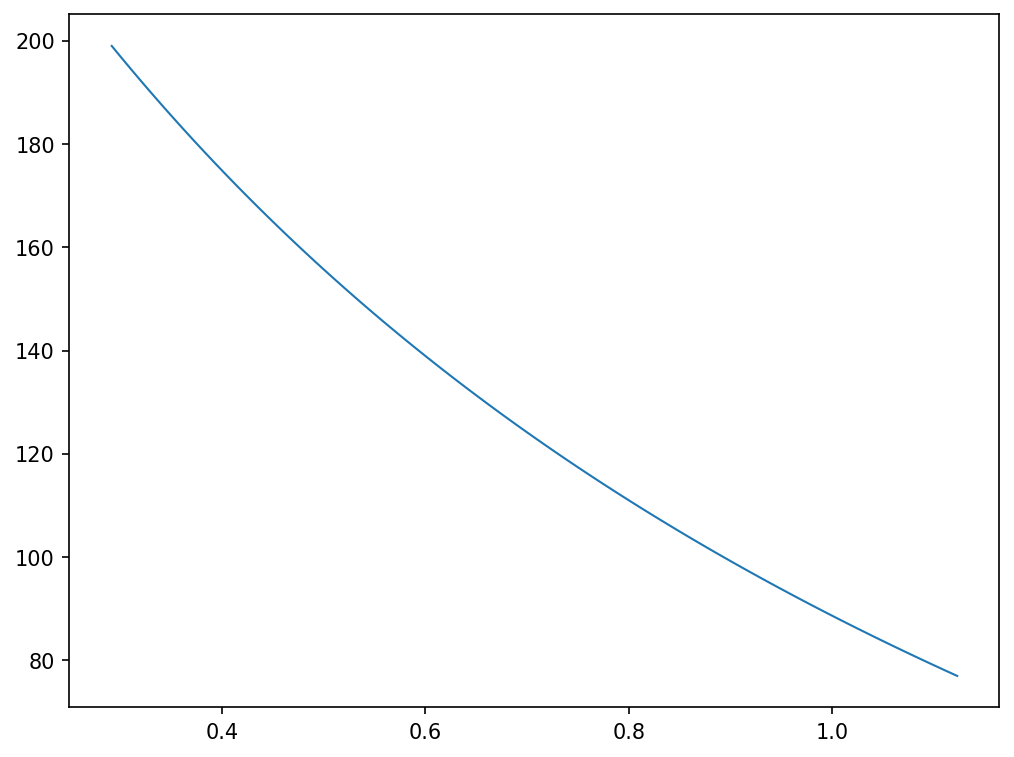

In [74]:
L = 199200
Cp = 1050

Te = np.arange(77,200,1)

n = (Cp * (290-Te) ) / ( L + (Te-77)* Cp )

plt.plot(n, Te)


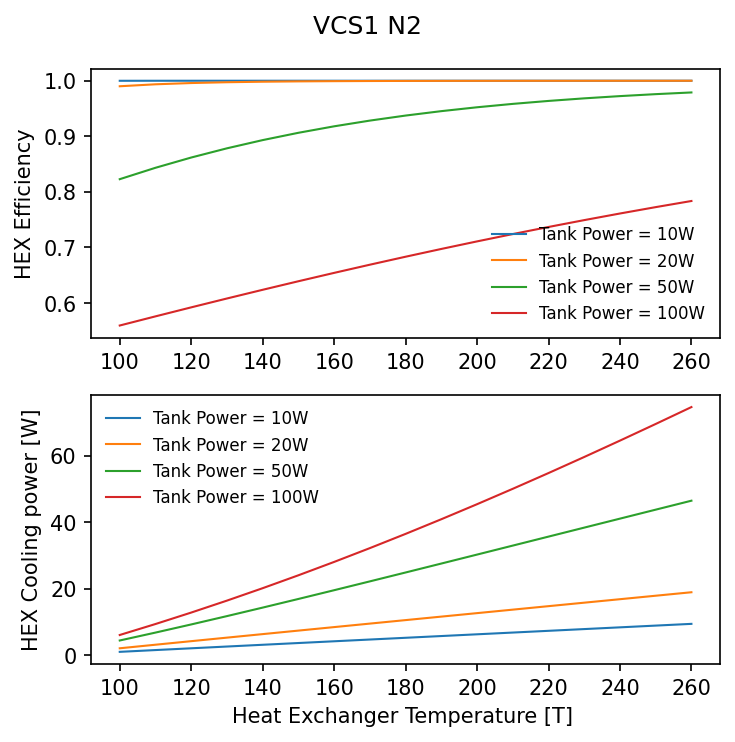

In [57]:
fig, ax = plt.subplots(2,1,figsize=(5,5),dpi=150)

for p in [ 10, 20, 50, 100]:

    T2s  = np.arange(100,261,10)
    Eff  = []
    CoolPower = []
    mdot = power2mdot(p, gas='N')
    
    for T2 in T2s:
        x,T = HexEff(T2, T0=80,  power=p, gas='N')
        Eff.append((T[-1]-T[0])/(T2-T[0])) 
        CoolPower.append((quad(NCp, T[0], T[-1], epsrel=1e-3)[0])*mdot)
    
    ax[0].plot(T2s, Eff, label='Tank Power = %1dW'%p)
    ax[1].plot(T2s, CoolPower, label='Tank Power = %1dW'%p)

ax[1].set_xlabel('Heat Exchanger Temperature [T] ')

ax[0].set_ylabel('HEX Efficiency')
ax[1].set_ylabel('HEX Cooling power [W]')

# plt.ylim([0,50])
ax[0].legend(frameon=0, fontsize=8)
# ax[0].grid()

ax[1].legend(frameon=0, fontsize=8)
# ax[1].grid()

plt.suptitle('VCS1 N2')

plt.tight_layout()

# plt.savefig('HEX_eff_vcs1_N2.png')

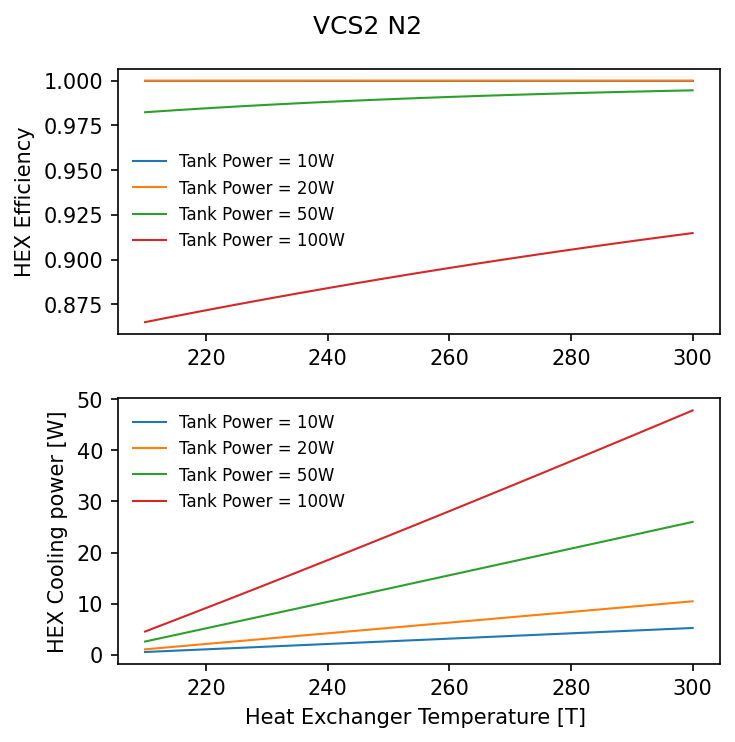

In [56]:
fig, ax = plt.subplots(2,1,figsize=(5,5),dpi=150)

for p in [ 10, 20, 50, 100]:

    T2s  = np.arange(210,301,5)
    Eff  = []
    CoolPower = []
    mdot = power2mdot(p, gas='N')

    for T2 in T2s:
        x,T = HexEff(T2, T0=200,  power=p, gas='N')
        Eff.append((T[-1]-T[0])/(T2-T[0])) 
        CoolPower.append((quad(NCp, T[0], T[-1], epsrel=1e-3)[0])*mdot)
        
    ax[0].plot(T2s, Eff, label='Tank Power = %1dW'%p)
    ax[1].plot(T2s, CoolPower, label='Tank Power = %1dW'%p)

ax[1].set_xlabel('Heat Exchanger Temperature [T] ')

ax[0].set_ylabel('HEX Efficiency')
ax[1].set_ylabel('HEX Cooling power [W]')
# ax[1].set_yscale('log')

# plt.ylim([0,50])
ax[0].legend(frameon=0, fontsize=8)
# ax[0].grid()

ax[1].legend(frameon=0, fontsize=8)
# ax[1].grid()

plt.suptitle('VCS2 N2')

plt.tight_layout()

# plt.savefig('HEX_eff_vcs2_N2.png')

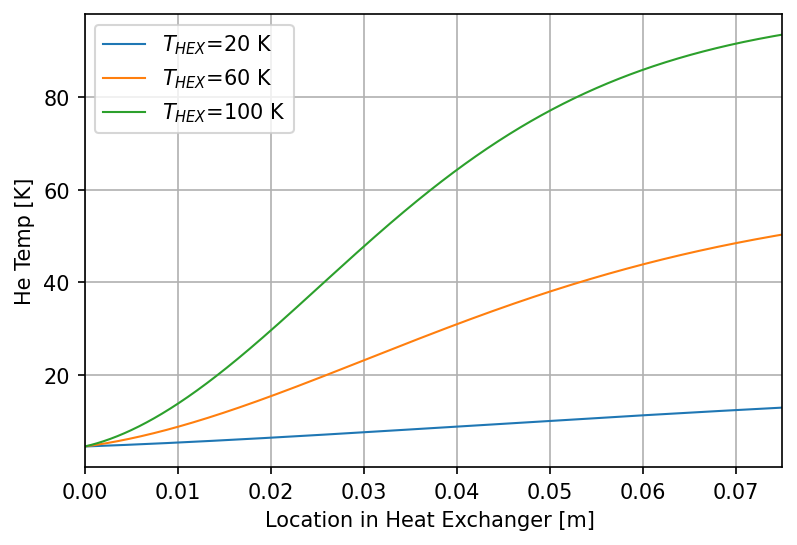

time: 593 ms (started: 2022-09-07 09:13:03 -05:00)


In [294]:
T2s  = np.arange(20,101,40)
T_profiles = []

   
fig, ax1 = plt.subplots(dpi=150)
    
for T2 in T2s:
    x,T = HexEff(T2, T0=4.5, power=4)
    plt.plot(x, T, label='$T_{HEX}$=%1d K'%T2)

plt.xlabel('Location in Heat Exchanger [m] ')
plt.ylabel('He Temp [K]')

plt.xlim([0,0.075])
plt.legend(loc='best')
plt.grid()

plt.savefig('HEX_temp_profile_vcs1.png')

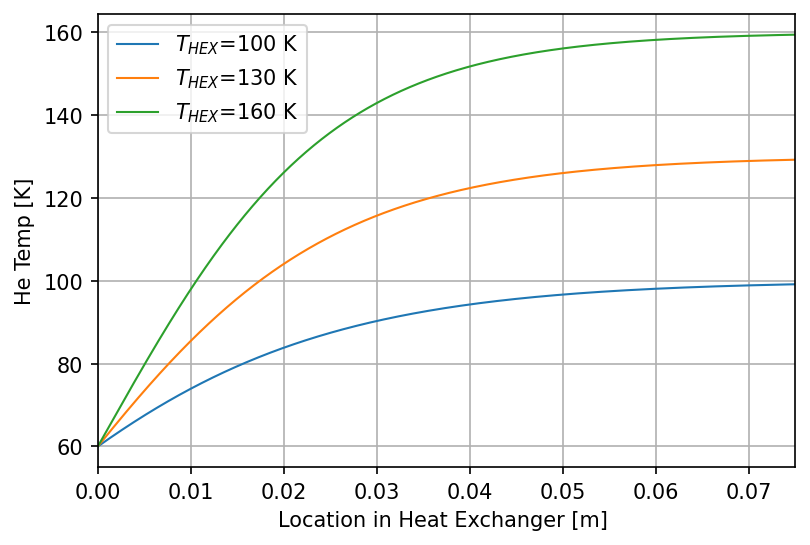

time: 512 ms (started: 2022-09-07 09:13:12 -05:00)


In [295]:
T2s  = np.arange(100,180,30)
T_profiles = []

   
fig, ax1 = plt.subplots(dpi=150)
    
for T2 in T2s:
    x,T = HexEff(T2, T0 = 60, power=4)
    plt.plot(x, T, label='$T_{HEX}$=%1d K'%T2)

plt.xlabel('Location in Heat Exchanger [m] ')
plt.ylabel('He Temp [K]')

plt.xlim([0,0.075])
plt.legend()
plt.grid()

# plt.savefig('HEX_temp_profile_vcs1.png')

In [1]:
def AlCp(T):
    # Return Al 6061 specific heat from 4-300K in J/(kg*K)
    coeff = np.vstack([46.6467,-314.292,866.662,-1298.3,1162.27,-637.795,210.351,-38.3094,2.96344])
    logT  = np.log10(T)
    logCv = np.power(logT, np.vstack(np.arange(0,9,1))) *coeff
    
    return 10**logCv.sum(axis=0)[0]   


In [8]:
M_shell = 45 #kg
p       = 1.



def func(T,p=1): 
    mdot = p/85*0.004
    return -1*M_shell*AlCp(T)/((T-4.5)*5.2e3*mdot)

Tmin = np.arange(80.1,10,-1)
t = []

for T in Tmin:
    t.append(quad(func, 81, T, epsrel=1e-3)[0])

def func(T,p=2): 
    mdot = p/85*0.004
    return -1*M_shell*AlCp(T)/((T-4.5)*5.2e3*mdot)

t2 = [] 
    
for T in Tmin:
    t2.append(quad(func, 81, T, epsrel=1e-3)[0])


t = np.array(t)  
t2 = np.array(t2)  


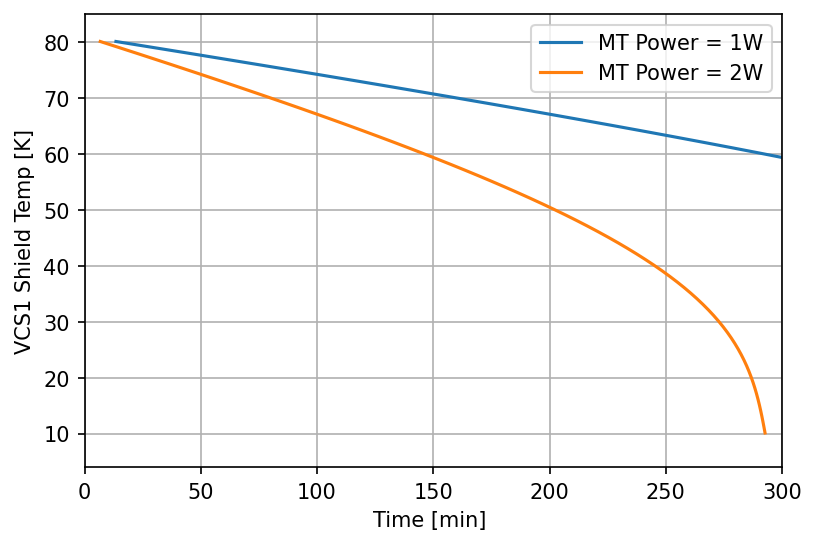

In [9]:

fig, ax1 = plt.subplots(dpi=150)
    
plt.plot(t/60,Tmin,label='MT Power = 1W')
plt.plot(t2/60,Tmin,label='MT Power = 2W')



plt.xlabel('Time [min] ')
plt.ylabel('VCS1 Shield Temp [K]')

plt.xlim([0,300])
plt.ylim([4,85])

plt.legend()
plt.grid()

# plt.savefig('HEX_temp_profile_vcs1.png')